# 05. 골드셋 최종 평가 · 모델 해석 · 종목명 없는 기사 적용 인사이트

1. 선정 모델의 골드 테스트셋 성능 (태그별 정밀도·재현율, Precision@1, Hamming loss)
2. 혼동 패턴과 오분류 사례 분석
3. 종목명 없는 기사(D3) 전체에 태깅 → 주별 태그 추이, 이슈 주간 사례, 태그 지수와의 비교

In [1]:
import sys, json
sys.path.insert(0, "..")
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from src.config import PROCESSED, GOLD, OUTPUTS, RAW, TAGS
from src.dataset import label_matrix, load_gold
from src.evaluate import multilabel_report, per_tag_report, apply_thresholds
from src.modeling import SavedTagger, as_frame
from src import viz
viz.setup()
pd.set_option("display.max_colwidth", 110)
MODELS = OUTPUTS / "models"

d3 = pd.read_pickle(PROCESSED / "d3_clean.pkl")
gold = load_gold()
gt = gold[gold.split == "test"].reset_index(drop=True)
Ygt = label_matrix(gt.tag_list)

best = json.load(open(MODELS / "best.json", encoding="utf-8"))["best_model"]
kind = {"Logistic Regression": "lr", "RandomForest": "rf", "XGBoost": "xgb"}[best]
tagger = SavedTagger(MODELS / f"{kind}.joblib")
print("선정 모델:", best)

선정 모델: Logistic Regression


## 1. 골드 테스트셋 최종 성능

In [2]:
P = tagger.proba(as_frame(gt))
Yp = apply_thresholds(P, tagger.thresholds)
overall = multilabel_report(Ygt, Yp, P)
pd.Series(overall).to_frame("골드 테스트 (200건)").T

,micro_f1,micro_precision,micro_recall,macro_f1,hamming_loss,none_accuracy,precision_at_1
골드 테스트 (200건),0.6218,0.5505,0.7143,0.5071,0.0243,0.71,0.8734


### 1-1. 테스트셋 200건의 불확실성 — 부트스트랩 신뢰구간
테스트셋이 작아(정답 태그 84개) 모델·실험 간 차이가 표본 잡음보다 큰지 확인한다. 기사 단위로 1,000번 복원 추출해
각 모델의 Micro F1 95% 구간과, 선정 모델과의 **짝지은 차이**(같은 표본에서 계산)의 구간을 본다.

In [3]:
from sklearn.metrics import f1_score
rng = np.random.default_rng(0)
boot_idx = [rng.integers(0, len(gt), len(gt)) for _ in range(1000)]
preds = {}
for name, k in [("Logistic Regression", "lr"), ("RandomForest", "rf"), ("XGBoost", "xgb")]:
    t_ = SavedTagger(MODELS / f"{k}.joblib")
    preds[name] = t_.predict(as_frame(gt))
def micro(Yt, Yp_): return f1_score(Yt, Yp_, average="micro", zero_division=0)
rows = []
for name, Yp_ in preds.items():
    vals = np.array([micro(Ygt[i], Yp_[i]) for i in boot_idx])
    diff = np.array([micro(Ygt[i], Yp_[i]) - micro(Ygt[i], preds[best][i]) for i in boot_idx])
    rows.append({"model": name, "micro_f1": round(micro(Ygt, Yp_), 3),
                 "95% CI": f"[{np.percentile(vals, 2.5):.3f}, {np.percentile(vals, 97.5):.3f}]",
                 f"{best} 대비 차이 95% CI": f"[{np.percentile(diff, 2.5):+.3f}, {np.percentile(diff, 97.5):+.3f}]",
                 f"{best}보다 낮을 확률": round(float((diff < 0).mean()), 3)})
boot = pd.DataFrame(rows)
boot.to_csv(OUTPUTS / "gold_bootstrap.csv", index=False, encoding="utf-8-sig")
boot

,model,micro_f1,95% CI,Logistic Regression 대비 차이 95% CI,Logistic Regression보다 낮을 확률
0,Logistic Regression,0.622,"[0.536, 0.698]","[+0.000, +0.000]",0.000
1,RandomForest,0.489,"[0.410, 0.567]","[-0.205, -0.064]",0.999
2,XGBoost,0.500,"[0.413, 0.580]","[-0.196, -0.039]",0.994


Micro F1의 95% 구간이 약 ±0.08이다. 따라서 04의 E3~E5에서 본 0.01~0.05 수준의 차이는 표본 잡음 안에 있을 수 있고,
방향만 참고해야 한다. 반면 LR과 RF·XGBoost의 차이(0.12~0.13)는 짝지은 차이 구간이 0을 포함하지 않는다.

In [4]:
pt = per_tag_report(Ygt, Yp, TAGS)
pt["threshold"] = tagger.thresholds.round(3)
pt = pt.sort_values("support", ascending=False)
pt.to_csv(OUTPUTS / "gold_per_tag.csv", index=False, encoding="utf-8-sig")
pt

,tag,precision,recall,f1,support,threshold
10,건설·부동산,0.667,1.000,0.800,14,0.425
9,금융(은행·증권·보험),0.524,0.917,0.667,12,0.800
11,정유·화학,0.545,0.667,0.600,9,0.950
0,반도체,0.800,0.500,0.615,8,0.800
12,항공·여행,0.600,0.857,0.706,7,0.800
5,원전·전력기기,0.833,0.714,0.769,7,0.800
4,철강·비철,0.800,0.800,0.800,5,0.800
13,화장품·소비재,0.500,0.500,0.500,4,0.800
14,엔터·미디어,0.333,0.500,0.400,4,0.800
2,자동차,0.250,0.250,0.250,4,0.800


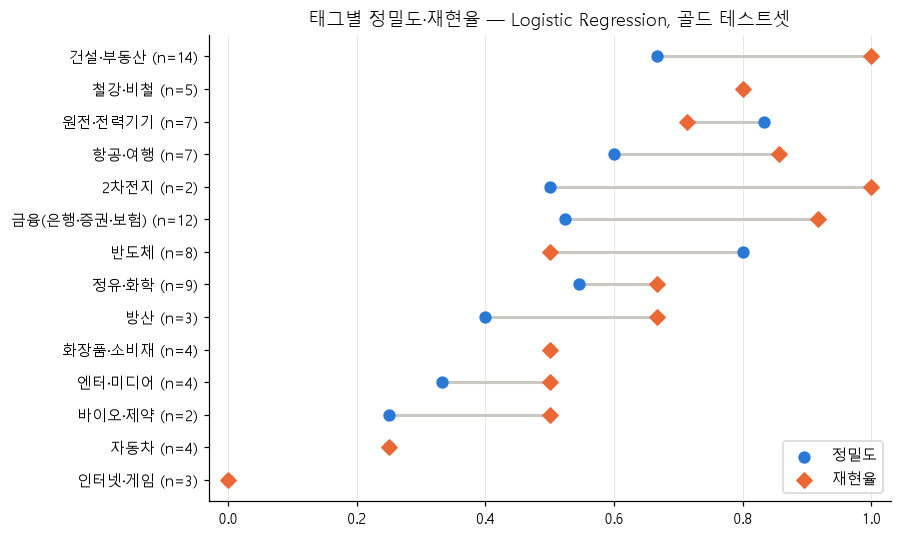

In [5]:
fig, ax = plt.subplots(figsize=(8, 5.5))
d = pt[pt.support > 0].sort_values("f1")
y = np.arange(len(d))
ax.scatter(d.precision, y, color=viz.BLUE, s=50, label="정밀도", zorder=3)
ax.scatter(d.recall, y, color=viz.ORANGE, s=50, marker="D", label="재현율", zorder=3)
for i, (p, r) in enumerate(zip(d.precision, d.recall)):
    ax.plot([p, r], [i, i], color="#c9c8c2", lw=2, zorder=1)
ax.set_yticks(y, [f"{t} (n={s})" for t, s in zip(d.tag, d.support)])
ax.set_xlim(-0.03, 1.03); ax.legend(loc="lower right"); ax.grid(axis="y", visible=False)
ax.set_title(f"태그별 정밀도·재현율 — {best}, 골드 테스트셋")
viz.save(fig, "gold_per_tag"); plt.show()

## 2. 혼동 패턴
정답 태그 A인 기사에 모델이 엉뚱하게 붙인 태그 B를 센다 (A의 정답 기사 중 B가 오탐으로 붙은 비율).

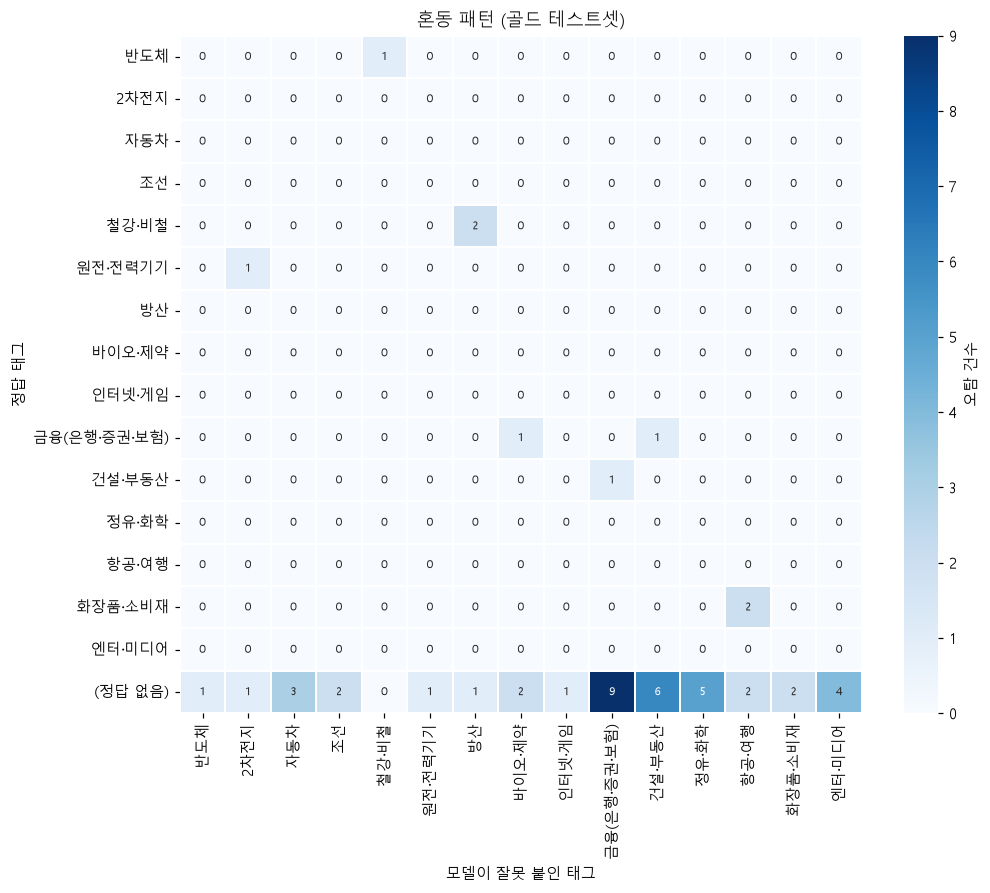

(정답 없음)  금융(은행·증권·보험)    9.0
         건설·부동산          6.0
         정유·화학           5.0
         엔터·미디어          4.0
         자동차             3.0
철강·비철    방산              2.0
(정답 없음)  조선              2.0
화장품·소비재  항공·여행           2.0
(정답 없음)  항공·여행           2.0
         화장품·소비재         2.0
dtype: float64

In [6]:
conf = np.zeros((len(TAGS), len(TAGS)))
for yt, yp in zip(Ygt, Yp):
    fp = np.where((yp == 1) & (yt == 0))[0]
    for a in np.where(yt == 1)[0]:
        conf[a, fp] += 1
none_fp = Yp[Ygt.sum(1) == 0].sum(0)  # '없음' 기사에 붙은 오탐
conf_df = pd.DataFrame(conf, index=TAGS, columns=TAGS)
conf_df.loc["(정답 없음)"] = none_fp
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(conf_df, cmap=viz.SEQ, annot=True, fmt=".0f", annot_kws={"size": 7}, ax=ax,
            linewidths=1, linecolor="white", cbar_kws={"label": "오탐 건수"})
ax.set_xlabel("모델이 잘못 붙인 태그"); ax.set_ylabel("정답 태그")
ax.set_title("혼동 패턴 (골드 테스트셋)")
viz.save(fig, "gold_confusion"); plt.show()
pairs = conf_df.stack().sort_values(ascending=False).head(10)
pairs[pairs > 0]

## 3. 오분류 사례 직접 읽기
오탐(FP)·미탐(FN)이 있는 기사 중 20건을 뽑아 원인을 분류한다.
원인 범주: **라벨 노이즈**(약한 라벨이 가르친 잘못된 연상), **도메인 차이**(일반 기사 어휘를 학습에서 못 봄),
**진짜 애매함**(골드 라벨 자체가 판단의 문제), **키워드 과민**(산업 단어가 나오지만 영향은 없는 기사).

In [7]:
gt["pred"] = [[t for t, v in zip(TAGS, r) if v] for r in Yp]
gt["top1"] = [f"{TAGS[i]} ({P[k, i]:.2f})" for k, i in enumerate(P.argmax(1))]
err = gt[gt.apply(lambda r: set(r.tag_list) != set(r.pred), axis=1)]
print(f"오분류 기사 {len(err)}/{len(gt)}건")
err_s = err.sample(min(20, len(err)), random_state=0)[["doc_id", "title_c", "desc_c", "tag_list", "pred", "top1"]].copy()
err_s["기사"] = err_s.title_c.str.slice(0, 40) + " | " + err_s.desc_c.str.slice(0, 50)
err_s[["doc_id", "기사", "tag_list", "pred", "top1"]].rename(columns={"tag_list": "정답", "pred": "예측", "top1": "확률 1위"})

오분류 기사 68/200건


,doc_id,기사,정답,예측,확률 1위
125,d3_e88959dbce,"'빨대'라더니…국힘 ""추미애의 경기도, 소방차 구매 축소·추모 예산 삭. | 도당은 ""추 지사는 '재정 빨대' 발언에 대해 소방 공무원들에게 직접 사과해야 한다""며 """,[],[자동차],자동차 (0.92)
64,d3_1b092a0480,"[끈적한 물가] 유가 충격에 수요 압력까지…물가 안정 늦추는 변수들 | 원화 가치가 상승하면 원유와 원자재의 수입 비용을 낮추는 효과가 있지만, 원·달러 환율이",[],[정유·화학],정유·화학 (0.96)
74,d3_ecbad746c3,"[2026 국감] 이소영 ""플랫폼 입점 수수료, 소상공인 옥죄는 수준…규 | 온라인 플랫폼에 입점한 소상공인들이 과도한 수수료와 광고비 부담을 떠안고 있다는 지적이 국",[인터넷·게임],[],화장품·소비재 (0.51)
54,d3_2e65bd5c78,"생명연, '성숙 심근세포' 만드는 기술 개발...신약 평가와 재생의료 활 | 이번 연구는 신약 개발 초기 단계에서 약물이 심장에 미치는 영향을 보다 사람과 유사한 조건",[],[바이오·제약],바이오·제약 (1.00)
70,d3_ff7fcd6346,구찌도 '메이드 인 차이나' 라벨…유럽 명품·자동차까지 넘보는 중국 | 독일 중앙은행 분석에 따르면 2019년 이후 중국의 수출 품목이 독일의 주력 상품인 공장,[],[자동차],자동차 (1.00)
112,d3_3a30fd31b7,"어피닛, 인도 최대 OTT에 브랜드 다큐 공개…금융 접근성 확대 스토리 | 온라인동영상서비스(OTT) 플랫폼 지오핫스타에 공개했다고 8일 밝혔다. 다큐멘터리는 일상에",[],[엔터·미디어],엔터·미디어 (0.88)
69,d3_bc9b980980,"광주은행-토스뱅크, '공동대출 서비스' 금융위 혁신금융서비스 지정 | 이어 ""경기침체와 금융비용 부담으로 자금조달에 어려움을 겪는 지역 소상공인과 중소기업에 실",[],[금융(은행·증권·보험)],금융(은행·증권·보험) (1.00)
175,d3_668c12cc99,"최휘영 ""K-컬처 저력 기초예술서 나와…투자 늘려"" | 더불어 ""K-컬처에 대한 세계적 관심이 연관 산업의 수출로 이어지도록 하겠다""며 ""K-콘텐",[엔터·미디어],[],엔터·미디어 (0.58)
149,d3_4a166ba514,특구 바이오기업 글로벌 경쟁력 높인다...특구재단·국가신약개발재단... | 연구개발특구진흥재단이 국가신약개발재단(KDDF)과 손잡고 연구개발특구 내 제약·바이오 기업,[],[바이오·제약],바이오·제약 (1.00)
177,d3_008dc64019,"핀다, 핀테크 최초 저축은행 인수 초읽기…비대면 영업에 승부 건다 | 부동산 프로젝트파이낸싱(PF) 부실 여파와 조달 비용 상승 등으로 저축은행 업권의 건전성",[],"[금융(은행·증권·보험), 건설·부동산]",건설·부동산 (0.96)


In [8]:
# 위 20건을 직접 읽고 단 원인
ERROR_CAUSE = {
    "d3_e88959dbce": "키워드 과민",   # 소방차 구매 예산 → '차량 구매'로 자동차
    "d3_1b092a0480": "키워드 과민",   # 물가 기사 속 유가 언급 → 정유
    "d3_ecbad746c3": "도메인 차이",   # 플랫폼 입점 수수료 규제 — 종목 기사에 드문 정책 어휘라 인터넷을 놓침
    "d3_2e65bd5c78": "진짜 애매함",   # 생명연 심근세포 기술(신약 평가용) — 연구기관 기사라 '없음'으로 달았지만 바이오로 볼 여지
    "d3_ff7fcd6346": "진짜 애매함",   # 중국 수출이 유럽 자동차를 위협 — 국내 완성차 영향 여부 판단의 문제
    "d3_3a30fd31b7": "키워드 과민",   # 금융사 브랜드 다큐를 OTT에 공개 → 'OTT'만 보고 엔터
    "d3_bc9b980980": "진짜 애매함",   # 지방은행·인터넷은행 공동대출 지정 — 은행 업계 기사지만 영향 미미하다고 봐 '없음'
    "d3_668c12cc99": "임계값",        # 문체부 장관 K-컬처 투자 → 엔터 확률 0.58 < 임계값 0.8
    "d3_4a166ba514": "진짜 애매함",   # 특구 바이오기업 지원 협약 → 바이오
    "d3_008dc64019": "진짜 애매함",   # 핀테크의 저축은행 인수 — 금융 영향으로 볼 수도 있음 (+ 'PF 부실'로 건설)
    "d3_9286c558f4": "진짜 애매함",   # 농·수협 상호금융 부동산 대출(비상장) → 금융
    "d3_b231d28f45": "진짜 애매함",   # 미국의 러시아 석유 제재법 — 정유 영향 가능
    "d3_bba0d2be54": "도메인 차이",   # 관세청 수출 통계(반도체 171%↑) → 반도체 대신 철강·비철. 통계 기사 문체를 학습에서 못 봄
    "d3_f1b12d8f6f": "키워드 과민",   # 대통령 국정 칼럼 속 '단일종목 레버리지' → 금융
    "d3_05bdb6cb71": "키워드 과민",   # 서비스산업발전법 기사 속 'K-콘텐츠' → 엔터
    "d3_445cde2b69": "도메인 차이",   # 유커 면세점 매출 → 항공·여행은 맞혔지만 '면세점 → 화장품' 연결을 못 배움
    "d3_0c1b17fa5a": "임계값",        # 원전 PPA·철강 전력 부담 → 원전 확률 0.78 < 임계값 0.8
    "d3_9ccbb5a62c": "임계값",        # 러시아산 경유·국제유가 → 정유 확률 0.56 < 정유 임계값 0.95
    "d3_4edfcc8222": "진짜 애매함",   # 건설업계 대출규제 완화 요구 → 건설(정답) + 금융. PF·대출규제는 금융 영향으로 볼 여지
    "d3_30761d3bec": "진짜 애매함",   # 마운자로 실손보험 청구 급증 → 금융(정답) + 바이오. 비만약 기사로 볼 여지
}
err_s["원인"] = err_s.doc_id.map(ERROR_CAUSE)
err_s["원인"].value_counts().rename("건수").to_frame().T

원인,진짜 애매함,키워드 과민,도메인 차이,임계값
건수,9,5,3,3


## 4. 종목명 없는 기사(D3) 전체 태깅

In [9]:
d3["pred"] = tagger.tag_lists(as_frame(d3))
P3 = tagger.proba(as_frame(d3))
d3["top_tag"] = [TAGS[i] for i in P3.argmax(1)]
d3["n_pred"] = d3.pred.str.len()
print(f"D3 {len(d3):,}건 중 태그 1개 이상: {(d3.n_pred > 0).mean():.1%}  (골드셋 정답 기준 비율: "
      f"{(label_matrix(gold.tag_list).sum(1) > 0).mean():.1%})")
d3.n_pred.value_counts().sort_index().rename("기사 수").to_frame().T

D3 70,581건 중 태그 1개 이상: 51.2%  (골드셋 정답 기준 비율: 39.3%)


n_pred,0,1,2,3
기사 수,34420,34128,2020,13


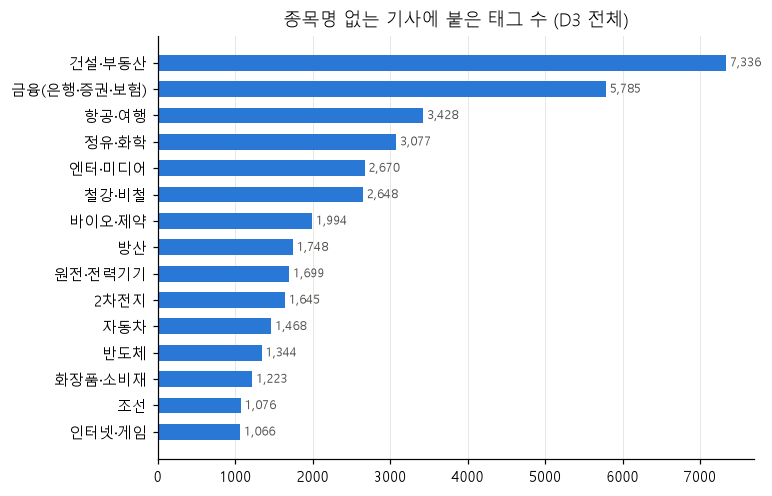

In [10]:
tag_cnt = pd.Series([t for ts in d3.pred for t in ts]).value_counts().reindex(TAGS, fill_value=0).sort_values()
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(tag_cnt.index, tag_cnt.values, color=viz.BLUE, height=0.6)
for y_, v in enumerate(tag_cnt.values):
    ax.text(v, y_, f" {v:,}", va="center", fontsize=8, color="#52514e")
ax.set_title("종목명 없는 기사에 붙은 태그 수 (D3 전체)"); ax.grid(axis="y", visible=False)
viz.save(fig, "d3_tag_counts"); plt.show()

In [11]:
print("거시 검색어 vs 산업 검색어로 모은 기사의 태깅 비율")
d3.groupby("query_group").n_pred.apply(lambda s: (s > 0).mean()).round(3)

거시 검색어 vs 산업 검색어로 모은 기사의 태깅 비율


query_group
industry    0.770
macro       0.287
Name: n_pred, dtype: float64

### 4-1. 주별 태그별 기사 수 추이

In [12]:
long = d3[["pub_date", "pred"]].explode("pred").dropna()
long["week"] = long.pub_date.dt.to_period("W").dt.start_time
weekly = long.groupby(["week", "pred"]).size().unstack(fill_value=0).reindex(columns=TAGS, fill_value=0)
total_week = d3.assign(week=d3.pub_date.dt.to_period("W").dt.start_time).groupby("week").size()
ok_weeks = total_week[total_week >= 30].index  # 표본이 너무 적은 주는 제외
weekly, total_week = weekly.loc[weekly.index.isin(ok_weeks)], total_week.loc[ok_weeks]
share = weekly.div(total_week, axis=0)
print(f"분석 주간 {len(ok_weeks)}개 ({ok_weeks.min():%Y-%m-%d} ~ {ok_weeks.max():%Y-%m-%d})")
fig = px.line(share.reset_index().melt(id_vars="week", var_name="태그", value_name="비중"),
              x="week", y="비중", facet_col="태그", facet_col_wrap=5, height=620,
              title="종목명 없는 기사 중 태그별 비중 (주별)", color_discrete_sequence=[viz.BLUE])
fig.update_yaxes(matches=None, tickformat=".0%", title=None)
fig.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))
fig.write_html(OUTPUTS / "d3_weekly_share.html"); fig.show()

분석 주간 53개 (2025-10-20 ~ 2026-10-19)


### 4-2. 이슈 주간: 태그가 급증한 주
주별 비중을 태그별 평균·표준편차로 표준화(z-score)해 2 이상인 주를 '급증'으로 본다.
해당 주에 그 태그가 붙은 기사 제목을 읽어 무슨 일이 있었는지 확인한다.

In [13]:
z = (share - share.mean()) / share.std(ddof=0)
spikes = z.stack().rename("z").reset_index().query("z >= 2").sort_values("z", ascending=False)
spikes.columns = ["week", "tag", "z"]
spikes["share"] = [share.loc[w, t] for w, t in zip(spikes.week, spikes.tag)]
spikes.head(12)

,week,tag,z,share
337,2026-03-23,바이오·제약,6.519149,0.434426
463,2026-05-18,화장품·소비재,5.229813,0.056701
171,2026-01-05,방산,5.057413,0.425150
258,2026-02-16,조선,4.156138,0.116279
440,2026-05-11,원전·전력기기,3.788787,0.097345
46,2025-11-10,2차전지,3.589482,0.106195
104,2025-12-01,엔터·미디어,3.295946,0.213235
555,2026-07-06,반도체,3.273111,0.042636
548,2026-06-29,인터넷·게임,2.985270,0.062331
260,2026-02-16,원전·전력기기,2.965572,0.081395


In [14]:
def spike_titles(week, tag, n=6):
    w = d3[(d3.pub_date.dt.to_period("W").dt.start_time == week) & d3.pred.map(lambda ts: tag in ts)]
    return w.sort_values("pub_date").title_c.head(n).tolist()

for _, r in spikes.head(4).iterrows():
    print(f"\n■ {r.week:%Y-%m-%d} 주 · {r.tag} (z={r.z:.1f}, 비중 {r.share:.1%})")
    for t in spike_titles(r.week, r.tag):
        print("  -", t)


■ 2026-03-23 주 · 바이오·제약 (z=6.5, 비중 43.4%)
  - 약가 인하 직격탄…제약 CSO업계 "수익 구조 붕괴 기로"
  - 혁신엔 프리미엄, 제네릭엔 인하…'양손 약가정책' 방향과 과제
  - '제네릭 약가 40%대 인하' 의결될까…업계 긴장
  - [들어보니] 제약바이오 주총 시즌 개막…“약가 인하 속 포트폴리오 다...
  - '약가인하 쓰나미' 덮치기 전인데 … 제약사 고용 꺾임세 뚜렷
  - 영세제약사 줄고 있는데…정부, 약가인하 통계 아전인수 해석

■ 2026-05-18 주 · 화장품·소비재 (z=5.2, 비중 5.7%)
  - 강원도, 美 보호무역 장벽에 맞서 '베트남·중국' 신흥 모빌리티 시장 ...
  - 토리든, 관광 연계형 K-뷰티 체험 프로그램을 확대...방한 관광객 겨냥
  - K-뷰티, 무역수지 101억 달러 첫 돌파…글로벌 위상 강화
  - 화장품 무역수지 흑자 첫 100억달러 돌파…세계 2위 수출국 달성
  - 韓 화장품, 작년 무역수지 첫 100억 달러 돌파
  - 화장품 무역수지 흑자 100억弗 돌파… 세계 2위 수출국으로

■ 2026-01-05 주 · 방산 (z=5.1, 비중 42.5%)
  - 북한, 日 '역대급 규모' 국방 예산 마련 비난…"군사대국화 야망 드러나...
  - [특징주] 구리 등 비철금속 가격 급등에 대창·서원 등 관련주 강세
  - 국민의힘, 국방 예산 1조 8000억원 지급 지연에 ‘진상조사’ 촉구
  - 구리 가격 '파죽지세'…t당 1만3천달러도 돌파
  - 구리 가격 ‘파죽지세’…t당 만 3천 달러도 돌파
  - 구리 가격 '파죽지세'…1t당 1만3천달러 사상 처음 돌파

■ 2026-02-16 주 · 조선 (z=4.2, 비중 11.6%)
  - 日 조선업 부활 선언, 당장 영향 없다지만…조선업계 '긴장'
  - 조선업계, 연초부터 해외 선박 건조 수주 잇따라
  - 조선업계, 中 LNG선 수주 확대에도 '잭팟' 자신감
  - 美 '마스가 행동계획' 발표…국내 조선업계 기

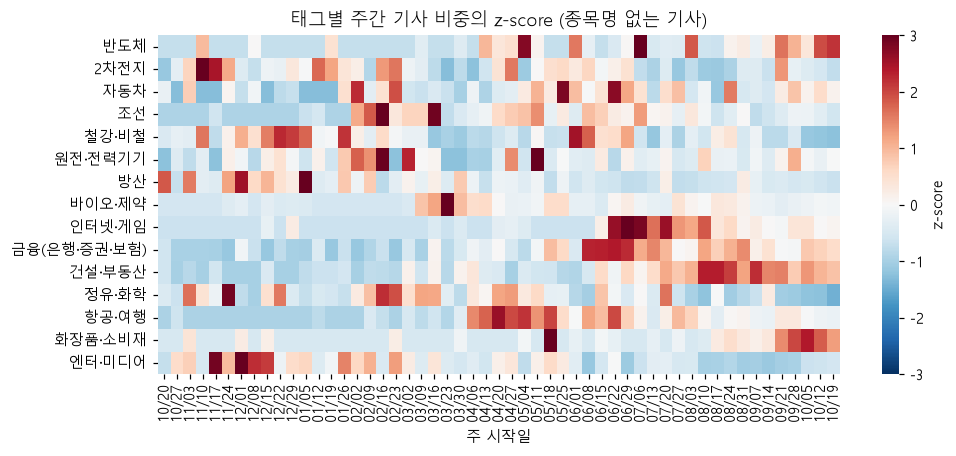

In [15]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.heatmap(z.T, cmap=viz.DIV, center=0, vmin=-3, vmax=3, ax=ax, cbar_kws={"label": "z-score"},
            xticklabels=[f"{w:%m/%d}" for w in z.index])
ax.set_xlabel("주 시작일"); ax.set_ylabel("")
ax.set_title("태그별 주간 기사 비중의 z-score (종목명 없는 기사)")
viz.save(fig, "d3_spike_heatmap"); plt.show()

### 4-3. (선택) 태그 기사 급증 vs 태그 지수 주간 수익률
태그 지수 = 대표 종목 동일가중(01 · D5). 같은 주의 '태그 기사 비중 z-score'와 '태그 지수 주간 수익률'의
상관을 본다. **상관관계 확인까지만 하며 인과로 해석하지 않는다.** 표본 주가 적고, 기사와 주가가 같은 사건에
동시에 반응하는 것일 뿐일 수 있다.

In [16]:
idx = pd.read_csv(RAW / "d5_tag_index.csv", index_col=0, parse_dates=True)
wret = idx.resample("W-SUN").last().pct_change()
wret.index = wret.index.to_period("W").start_time
wret_abs = wret.abs()
rows = []
for tag in TAGS:
    j = pd.concat([z[tag], wret[tag], wret_abs[tag]], axis=1, keys=["z", "ret", "abs_ret"]).dropna()
    if len(j) >= 6:
        rows.append({"tag": tag, "주 수": len(j), "corr(z, 수익률)": j.z.corr(j.ret),
                     "corr(z, |수익률|)": j.z.corr(j.abs_ret)})
corr = pd.DataFrame(rows).set_index("tag").round(2)
corr.sort_values("corr(z, |수익률|)", ascending=False)

,주 수,"corr(z, 수익률)","corr(z, |수익률|)"
tag,,,
인터넷·게임,53,0.08,0.36
건설·부동산,53,0.07,0.22
방산,53,0.33,0.21
조선,53,0.06,0.14
엔터·미디어,53,-0.01,0.10
자동차,53,-0.13,0.10
철강·비철,53,0.03,0.09
원전·전력기기,53,-0.05,0.03
정유·화학,53,0.05,0.03


In [17]:
print("태그 평균 상관 — 수익률:", corr["corr(z, 수익률)"].mean().round(3),
      "| 절대수익률:", corr["corr(z, |수익률|)"].mean().round(3))

태그 평균 상관 — 수익률: -0.005 | 절대수익률: 0.061


In [18]:
for _, r in spikes.head(4).iterrows():
    w = r.week
    rr = wret.loc[w, r.tag] if w in wret.index else np.nan
    print(f"{w:%Y-%m-%d} 주 {r.tag}: 기사 비중 z={r.z:.1f}, 태그 지수 주간 수익률 {rr:+.1%}")

2026-03-23 주 바이오·제약: 기사 비중 z=6.5, 태그 지수 주간 수익률 +2.5%
2026-05-18 주 화장품·소비재: 기사 비중 z=5.2, 태그 지수 주간 수익률 -3.3%
2026-01-05 주 방산: 기사 비중 z=5.1, 태그 지수 주간 수익률 +17.1%
2026-02-16 주 조선: 기사 비중 z=4.2, 태그 지수 주간 수익률 +11.6%


## 5. 사용 예시: 새 기사 태깅

In [19]:
from src.text import clean, tokenize_many
from src.masking import default_masker
def tag_articles(titles, descs=None):
    descs = descs or [""] * len(titles)
    text = [default_masker().mask(clean(t) + " . " + clean(d)) for t, d in zip(titles, descs)]
    X = pd.DataFrame({"tokens": tokenize_many(text), "text": text, "press": "unknown",
                      "log_len": np.log1p([len(t) for t in text])})
    P_ = tagger.proba(X)
    return pd.DataFrame({"기사": titles, "태그": tagger.tag_lists(X),
                         "상위 확률": [", ".join(f"{TAGS[i]} {p[i]:.2f}" for i in np.argsort(-p)[:3]) for p in P_]})

tag_articles(["美 관세 25% 부과 검토…완성차 수출 비상", "HBM 공급 부족 지속, 메모리 가격 상승세",
              "체코 원전 본계약 임박", "기준금리 동결…가계대출 증가세 우려", "중국 단체관광객 무비자 입국 확대",
              "서울 아파트값 상승폭 확대", "날씨 쌀쌀해진 주말 나들이객 붐벼"])

,기사,태그,상위 확률
0,美 관세 25% 부과 검토…완성차 수출 비상,[자동차],"자동차 0.97, 철강·비철 0.12, 방산 0.06"
1,"HBM 공급 부족 지속, 메모리 가격 상승세",[반도체],"반도체 0.99, 금융(은행·증권·보험) 0.02, 2차전지 0.02"
2,체코 원전 본계약 임박,[원전·전력기기],"원전·전력기기 0.97, 자동차 0.01, 조선 0.01"
3,기준금리 동결…가계대출 증가세 우려,[],"금융(은행·증권·보험) 0.65, 엔터·미디어 0.13, 화장품·소비재 0.05"
4,중국 단체관광객 무비자 입국 확대,[항공·여행],"항공·여행 0.96, 엔터·미디어 0.01, 바이오·제약 0.00"
5,서울 아파트값 상승폭 확대,[건설·부동산],"건설·부동산 0.48, 정유·화학 0.22, 바이오·제약 0.07"
6,날씨 쌀쌀해진 주말 나들이객 붐벼,[],"정유·화학 0.23, 금융(은행·증권·보험) 0.09, 자동차 0.04"


## 이 단계에서 알게 된 것

- **최종 성능 (LR, 골드 테스트 200건)**: Micro F1 0.622 [95% CI 0.536~0.698], 정밀도 0.551, 재현율 0.714,
  Macro F1 0.507, Precision@1 0.873, Hamming loss 0.024, '없음' 판정 정확도 0.71.
  → 정답 태그가 있는 기사에서는 1위 태그가 87% 맞지만(Precision@1), '없음' 기사 121건 중 32%에도 태그가 붙는다.
  **산업 구분보다 '관련 있는 기사인가' 판단이 약점**이라, 자동 알림보다 사람이 검토하는 보조 도구로 먼저 쓰는 게 맞다(README 7절).
  RF(0.489)·XGBoost(0.500)보다 낮을 부트스트랩 확률은 0.1%·0.6%다.
- **태그별**: 건설·부동산(F1 0.80)·철강·비철(0.80)·원전·전력기기(0.77)·항공·여행(0.71)은 잘 맞고, 인터넷·게임(0)·자동차(0.25)·
  바이오·제약(0.33)은 어렵다. 골드 테스트에서 태그당 양성이 0~14개라 태그별 수치는 흔들림이 크다.
- **오탐의 주 원인은 '키워드 과민'**: 정답이 없는 기사에 붙은 오탐은 금융(9건)·건설(6)·정유(5)·엔터(4) 순이다.
  금리·유가·주택·OTT 같은 단어만 나와도 해당 산업으로 끌려간다. 오분류 68건 중 20건 분류: 진짜 애매함 9, 키워드 과민 5,
  도메인 차이 3, 임계값 3. **절반가량은 라벨 판단 자체가 갈리는 기사**라 골드셋 이중 라벨링이 필요하다.
  임계값 3건은 정답 태그 확률이 0.56~0.78로 1위였는데 임계값(0.8·0.95)에 못 미쳤다 — 정밀도를 위해 재현율을 내준 결과다.
- **라벨 노이즈 실례**: 풍산(철강·비철+방산) 때문에 모델이 '구리 → 방산'을 배웠다(혼동 행렬에서 철강·비철 기사에 방산 오탐 2건).
  D3 급증 분석에서도 2026-01-05 주 '방산' 급증 기사 6건 중 3건이 구리 가격 기사였다. 두 산업에 걸친 종목은 태그 2개를 주기보다
  **학습에서 빼는 편**이 낫다.
- **D3 적용**: 7.06만 건 중 51%에 태그가 붙어 골드셋 정답 비율(39%)보다 많다(과다 태깅). 산업 검색어로 모은 기사는 77%,
  거시 검색어 기사는 29%가 태깅됐다.
- **이슈 주간**: 2026-03-23 주 바이오·제약(제네릭 약가 인하 의결), 2026-05-18 주 화장품(화장품 무역흑자 첫 100억 달러),
  2026-02-16 주 조선(일본 조선업 부활 선언·LNG선 수주), 2026-05-11 주 원전·전력기기(원전수출기획위원회 신설) 등
  태그 급증이 실제 정책·산업 이슈와 맞았다. 반면 2026-02-16 주 원전·전력기기 급증(z=3.0)은 비상장사 HET(에이치이티)의
  변압기 설비 투자 기사 7건이 몰린 것으로, 비상장사명은 D3 필터에 걸리지 않는다는 한계가 드러났다.
- **태그 지수와의 관계**: 태그 기사 비중 z-score와 같은 주 태그 지수 수익률의 상관은 평균 −0.01, 절대수익률과는 0.06으로
  뚜렷한 관계가 없다(방산 수익률 0.33, 인터넷·게임 |수익률| 0.36이 예외). 급증 상위 4주 중 3주는 지수도 올랐지만
  (방산 +17.1%, 조선 +11.6%, 바이오 +2.5%; 화장품 −3.3%), 표본이 작고 같은 사건에 동시에 반응한 것일 수 있어
  **상관관계 확인까지만** 한다.